<a href="https://colab.research.google.com/github/goswamijenya-bit/Applied-Data-Science-1/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Unzip the dataset (the zip must be uploaded to Colab first)
with zipfile.ZipFile("/content/sample_data/bike+sharing+dataset.zip") as z:
    z.extractall("bike_data")

# Load the daily data
day = pd.read_csv("bike_data/day.csv")

# First inspection
print(day.shape)
print(day.head())
day.info()
print("Missing values:", day.isna().sum().sum())
print("Duplicate rows:", day.duplicated().sum())

(731, 16)
   instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1        0        6           0   
1        2  2011-01-02       1   0     1        0        0           0   
2        3  2011-01-03       1   0     1        0        1           1   
3        4  2011-01-04       1   0     1        0        2           1   
4        5  2011-01-05       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   0.160296     108        1454   
4           1  0.226957  0.229270  0.436957   0.186900      82        1518   

    cnt  
0   985  
1   801  
2  1349  
3  1562  
4  1600  
<class 'pandas.c

In [ ]:
# --- 1. Convert the date column from text to a real date ---
day["dteday"] = pd.to_datetime(day["dteday"])

# --- 2. Consistency checks ---
# casual + registered should equal the total count
print("casual + registered == cnt:", (day["casual"] + day["registered"] == day["cnt"]).all())

# Humidity of exactly 0 is not realistic -> treat as a data error
print("Rows with humidity = 0:")
print(day.loc[day["hum"] == 0, ["dteday", "hum", "cnt"]])

# Replace the error with NaN, then fill it from the neighbouring days
day.loc[day["hum"] == 0, "hum"] = np.nan
day["hum"] = day["hum"].interpolate()

# --- 3. Convert normalised weather values back to real units (see Readme) ---
day["temp_c"] = day["temp"] * 41           # degrees Celsius
day["hum_pct"] = day["hum"] * 100          # humidity in %
day["wind_kmh"] = day["windspeed"] * 67    # wind speed (km/h)

# --- 4. Replace numeric codes with readable labels ---
# The Readme season labels do not match the data (season 1 contains January),
# so we label by the real calendar seasons
day["season_name"] = day["season"].map({1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"})
day["weather"] = day["weathersit"].map({1: "Clear", 2: "Mist / Cloudy", 3: "Light rain / snow"})
day["year"] = day["yr"].map({0: 2011, 1: 2012})
day["day_name"] = day["dteday"].dt.day_name()
day["month_name"] = day["dteday"].dt.strftime("%b")

# --- 5. Check the result ---
print(day[["dteday", "season_name", "weather", "temp_c", "hum_pct", "wind_kmh", "cnt"]].head())
print(day[["temp_c", "hum_pct", "wind_kmh", "cnt"]].describe().round(1))
print(day["weather"].value_counts())

casual + registered == cnt: True
Rows with humidity = 0:
       dteday  hum  cnt
68 2011-03-10  0.0  623
      dteday season_name        weather     temp_c  hum_pct   wind_kmh   cnt
0 2011-01-01      Winter  Mist / Cloudy  14.110847  80.5833  10.749882   985
1 2011-01-02      Winter  Mist / Cloudy  14.902598  69.6087  16.652113   801
2 2011-01-03      Winter          Clear   8.050924  43.7273  16.636703  1349
3 2011-01-04      Winter          Clear   8.200000  59.0435  10.739832  1562
4 2011-01-05      Winter          Clear   9.305237  43.6957  12.522300  1600
       temp_c  hum_pct  wind_kmh     cnt
count   731.0    731.0     731.0   731.0
mean     20.3     62.9      12.8  4504.3
std       7.5     14.1       5.2  1937.2
min       2.4     18.8       1.5    22.0
25%      13.8     52.1       9.0  3152.0
50%      20.4     62.7      12.1  4548.0
75%      26.9     73.0      15.6  5956.0
max      35.3     97.2      34.0  8714.0
weather
Clear                463
Mist / Cloudy        247
Light 

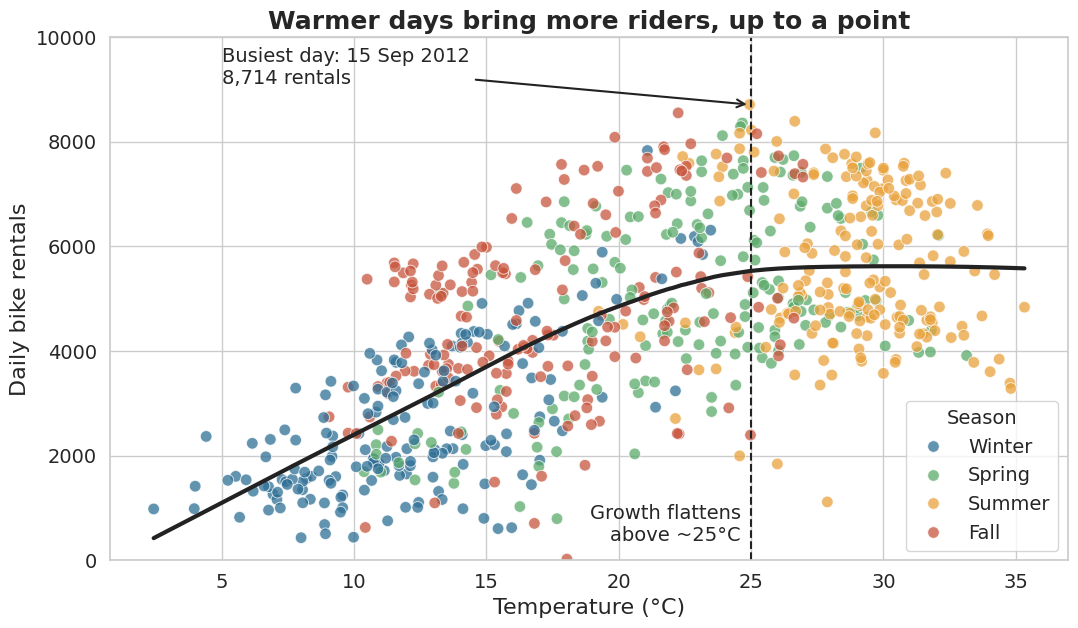

In [ ]:
# Global style: every font is 14 or larger (assignment requirement)
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.size": 14, "axes.titlesize": 18, "axes.labelsize": 16,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14,
    "legend.title_fontsize": 14, "axes.titleweight": "bold"
})

# Colours for the seasons (same colours will be reused in later plots)
SEASON_COLOURS = {"Winter": "#2E6F95", "Spring": "#5BAA6A", "Summer": "#E9A23B", "Fall": "#C8553D"}
SEASON_ORDER = ["Winter", "Spring", "Summer", "Fall"]


def plot_temp_vs_rentals(data):
    """Scatter plot of temperature vs daily rentals, coloured by season,
    with an overall trend line and annotations."""
    fig, ax = plt.subplots(figsize=(11, 6.5))

    # One dot per day, coloured by season
    sns.scatterplot(data=data, x="temp_c", y="cnt", hue="season_name",
                    hue_order=SEASON_ORDER, palette=SEASON_COLOURS,
                    s=70, alpha=0.75, edgecolor="white", ax=ax)

    # Overall trend: a smooth curve (lowess) so we can see where growth levels off
    sns.regplot(data=data, x="temp_c", y="cnt", scatter=False, lowess=True,
                line_kws={"color": "#222222", "linewidth": 3}, ax=ax)

    # Annotation 1: a dashed line where the trend flattens, with a label in the empty bottom-right area
    ax.axvline(25, color="#222222", linestyle="--", linewidth=1.5)
    ax.text(24.6, 300, "Growth flattens\nabove ~25°C", fontsize=14, va="bottom", ha="right")

    # Annotation 2: the busiest day, labelled in the empty top-left area
    peak = data.loc[data["cnt"].idxmax()]
    ax.annotate(f"Busiest day: {peak['dteday']:%d %b %Y}\n{peak['cnt']:,} rentals",
                xy=(peak["temp_c"], peak["cnt"]), xytext=(5, 9100), fontsize=14,
                arrowprops=dict(arrowstyle="->", color="#222222", lw=1.5))

    ax.set_title("Warmer days bring more riders, up to a point")
    ax.set_xlabel("Temperature (°C)")
    ax.set_ylabel("Daily bike rentals")
    ax.set_ylim(0, 10000)
    ax.legend(title="Season", loc="lower right", frameon=True)
    plt.tight_layout()
    plt.show()


plot_temp_vs_rentals(day)


# Problem 1 – Plot 1: Temperature and daily rentals
**Purpose.** I made a scatter plot to examine how weather influences demand because both Temperature and Rentals are continuous and a scatter plot displays each day separately. Colour represents Season and the black curve (a LOWESS trend) illustrates the overall pattern.

**What it shows.**
- Rentals increase steadily with Temperature (correlation = 0.63). Days at 5–10 °C average 1,700 Rentals whereas days at 25–30 °C average about 5,700 Rentals.
- Above roughly 25 °C the growth of Rentals. The curve flattens, with a slight decline after 30 °C. Riders favour weather, not hot weather.
- The busiest day (15 Sep 2012 8,714 Rentals) occurred at about 25 °C.

**Interesting detail:** At the Temperature Fall days (red) generate more Rentals than Winter days (blue). At 10–15 °C, Fall days average 4,300 Rentals and Winter days about 2,700 Rentals. 2012 Days average 4,000 Rentals at 10–15 °C compared with about 2,400 Rentals in 2011 suggesting system growth between years rather than purely weather effects. I plan to investigate this in the next plots.

**Design choices.** I used one colour for each Season ( used in later plots) a smooth trend line instead of a straight line because the relationship bends and I placed annotations, in empty areas so they do not cover data. All fonts are size 14 or larger.

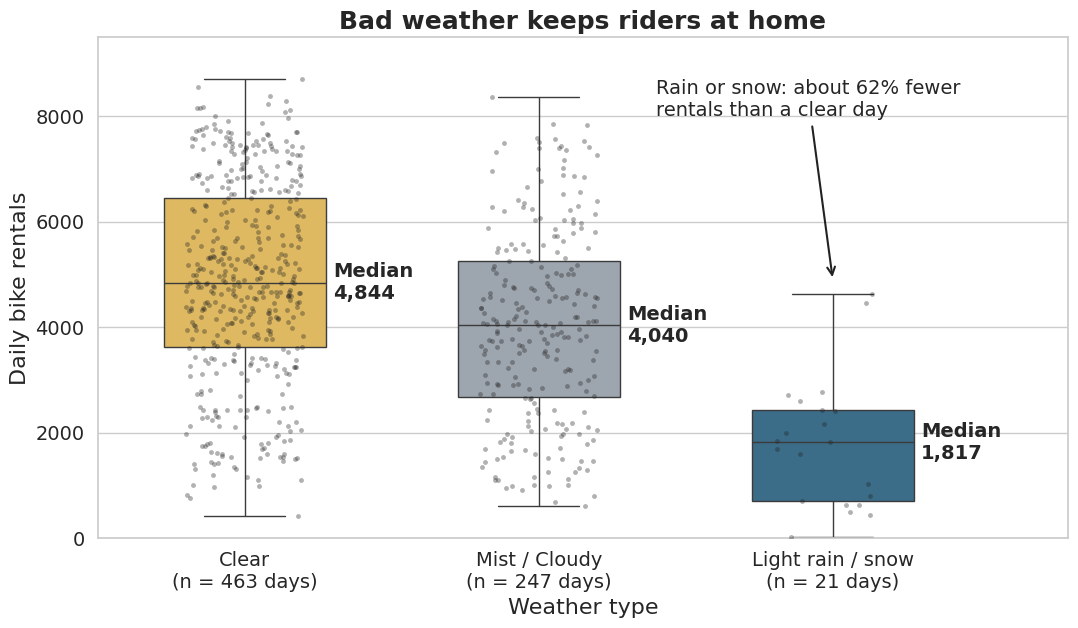

In [ ]:
def plot_rentals_by_weather(data):
    """Box plot of daily rentals for each weather type, with every day shown as a dot."""
    weather_order = ["Clear", "Mist / Cloudy", "Light rain / snow"]
    weather_colours = {"Clear": "#F2C14E", "Mist / Cloudy": "#9AA5B1", "Light rain / snow": "#2E6F95"}

    # Put the number of days in each x-axis label, so the small rain sample is obvious
    counts = data["weather"].value_counts()
    labels = [f"{w}\n(n = {counts[w]} days)" for w in weather_order]

    fig, ax = plt.subplots(figsize=(11, 6.5))

    # Box plot: median, quartiles and range for each weather type
    sns.boxplot(data=data, x="weather", y="cnt", order=weather_order,
                hue="weather", palette=weather_colours, legend=False,
                width=0.55, fliersize=0, ax=ax)

    # Dots: every single day, so the reader sees the real spread and sample size
    sns.stripplot(data=data, x="weather", y="cnt", order=weather_order,
                  color="#222222", size=3.5, alpha=0.35, jitter=0.2, ax=ax)

    # Annotate the median of each group
    medians = data.groupby("weather")["cnt"].median()
    for i, w in enumerate(weather_order):
        ax.text(i + 0.30, medians[w], f"Median\n{medians[w]:,.0f}", fontsize=14,
                va="center", fontweight="bold")

    # Annotation: how big the drop is compared with clear days
    drop = (1 - medians["Light rain / snow"] / medians["Clear"]) * 100
    ax.annotate(f"Rain or snow: about {drop:.0f}% fewer\nrentals than a clear day",
                xy=(2, 4900), xytext=(1.4, 8000), fontsize=14,
                arrowprops=dict(arrowstyle="->", color="#222222", lw=1.5))

    ax.set_xticks(range(3))
    ax.set_xticklabels(labels)
    ax.set_title("Bad weather keeps riders at home")
    ax.set_xlabel("Weather type")
    ax.set_ylabel("Daily bike rentals")
    ax.set_xlim(-0.5, 2.8)    # extra room on the right for the median labels
    ax.set_ylim(0, 9500)
    plt.tight_layout()
    plt.show()


plot_rentals_by_weather(day)

##Problem 1 – Plot 2: Rentals by weather type

**Purpose.** I used a box plot to compare Rentals across three weather types. Box plots display the median. Spread for each group and this detail would be missed by a simple average. I added a dot for each day so readers can see the sample sizes, the small rainy group.

**What it shows.**
- Rentals drop when the weather gets worse. The median Rentals are 4,844 on clear days 4,040 on misty days and 1,817 on rainy or snowy days. That means Rentals are 17% lower in mist and 62% lower in rain or snow compared to days.
- The Clear and Mist boxes overlap a lot. The middle half of day Rentals is roughly 3,600–6,500 and Mist Rentals are roughly 2,700–5,300. Thus Mist alone does not stop people from riding. Rain or snow does.
- 21 days fall into the rain/snow group so this result is less certain than the results for Clear and Mist.

**Interesting detail:** the day in the whole dataset—22 Rentals on 29 Oct 2012—was a rainy/snowy day. That date matches Hurricane Sandy hitting the US East Coast. This may explain the Rentals although the dataset does not say so.

**Design choices.** I used a box plot with dots than a bar chart of averages to show spread and sample size. I used colours that go from yellow for clear to cool blue, for rain. I included the sample size in each axis label. Added median labels so readers do not need to estimate from the axis.

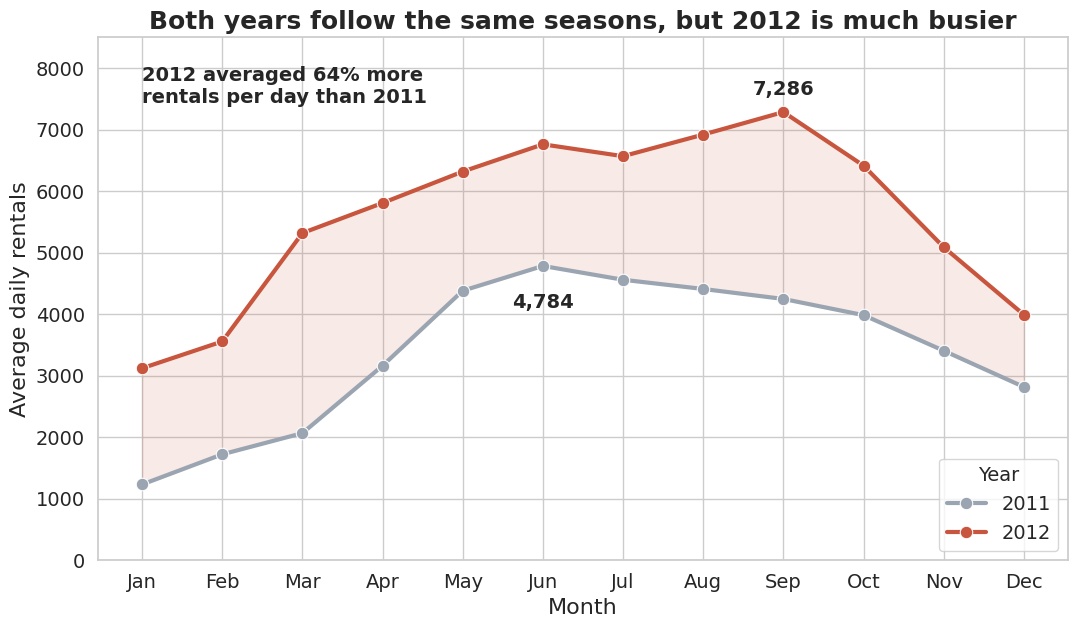

In [ ]:
def plot_monthly_growth(data):
    """Line chart of average daily rentals for each month, one line per year."""
    # Average daily rentals per month and year (average, not total, so month length does not matter)
    monthly = (data.groupby(["year", "mnth"], as_index=False)["cnt"].mean())
    month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

    year_colours = {2011: "#9AA5B1", 2012: "#C8553D"}

    fig, ax = plt.subplots(figsize=(11, 6.5))

    sns.lineplot(data=monthly, x="mnth", y="cnt", hue="year", palette=year_colours,
                 marker="o", markersize=9, linewidth=3, ax=ax)

    # Shade the gap between the two years so the growth is easy to see
    pivot = monthly.pivot(index="mnth", columns="year", values="cnt")
    ax.fill_between(pivot.index, pivot[2011], pivot[2012], color="#C8553D", alpha=0.12)

    # Annotation 1: overall growth between the two years
    growth = (data.loc[data["year"] == 2012, "cnt"].mean() /
              data.loc[data["year"] == 2011, "cnt"].mean() - 1) * 100
    ax.text(1.0, 7700, f"2012 averaged {growth:.0f}% more\nrentals per day than 2011",
            fontsize=14, fontweight="bold", va="center")

    # Annotation 2: the seasonal peak in each year
    for yr in [2011, 2012]:
        peak = monthly[monthly["year"] == yr].sort_values("cnt").iloc[-1]
        offset = (0, -30) if yr == 2011 else (0, 12)
        ax.annotate(f"{peak['cnt']:,.0f}", xy=(peak["mnth"], peak["cnt"]),
                    xytext=offset, textcoords="offset points",
                    ha="center", fontsize=14, fontweight="bold")

    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_labels)
    ax.set_title("Both years follow the same seasons, but 2012 is much busier")
    ax.set_xlabel("Month")
    ax.set_ylabel("Average daily rentals")
    ax.set_ylim(0, 8500)
    ax.legend(title="Year", loc="lower right")
    plt.tight_layout()
    plt.show()


plot_monthly_growth(day)

##Problem 1 – Plot 3: rentals in 2011 versus 2012

**Purpose.** In Plot 1 when the temperature was the same rentals in 2012 were higher than rentals in 2011. That made me think the system had grown between 2011 and 2012. A line chart is the way to check this because it shows how a number changes through an ordered sequence, like months and lets me line up 2011 and 2012 side by side. I used the daily rentals for each month not the total monthly rentals, so that months with 31 days do not get an advantage over shorter months.

**What it shows.**
- Both 2011 and 2012 follow the seasonal pattern. Rentals are lowest in January rise during spring reach a peak in summer or early fall and then drop toward December.
- Rentals in 2012 are above rentals in 2011 for every month. On average rentals in 2012 are 64% higher than rentals in 2011, 5,600 rentals per day versus 3,400 rentals per day. This backs up my idea from Plot 1: the gap where rentals in fall are higher than rentals in winter is largely due to growth not just weather.
- The highest points are around 4,784 rentals in June 2011. 7,286 Rentals in September 2012.

**Interesting detail.** The difference between rentals in 2012 and rentals in 2011 is biggest in the months of the year. Rentals in 2012 from January to March are 107% to 157% higher than rentals in 2011. In summer the difference is about 41% to 57%. One idea is that the system was still new in 2011 and was growing fast but the data does not confirm that so this is only a guess. Registered users also grew faster than users. Rentals per day for registered users increased 68% while rentals per day for casual users increased, about 50%. So most of the growth came from members.

**Design choices.** I chose one colour for each year. Grey is used for 2011, the older year and red is used for 2012, the year so the eye is drawn to 2012.

In [ ]:
# Load the hourly dataset used for Problem 2
hourly = pd.read_csv("/content/sample_data/dataset_x.csv")

print(hourly.shape)
print(hourly.head())
print("Missing values:", hourly.isna().sum().sum())
print("Duplicate rows:", hourly.duplicated().sum())

# The dates are written day/month/year, so we must tell pandas the format
hourly["dteday"] = pd.to_datetime(hourly["dteday"], format="%d/%m/%Y")

# Consistency checks
print("casual + registered == cnt:", (hourly["casual"] + hourly["registered"] == hourly["cnt"]).all())
print("Hours covered:", hourly["hr"].min(), "to", hourly["hr"].max())
print("Rows with humidity = 0:", (hourly["hum"] == 0).sum())
print("Dates of those rows:", hourly.loc[hourly["hum"] == 0, "dteday"].dt.date.unique())

# Readable labels (same season labels as Problem 1, based on the real calendar)
hourly["season_name"] = hourly["season"].map({1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"})
day_names = {0: "Sunday", 1: "Monday", 2: "Tuesday", 3: "Wednesday",
             4: "Thursday", 5: "Friday", 6: "Saturday"}
hourly["day_name"] = hourly["weekday"].map(day_names)
hourly["day_type"] = hourly["workingday"].map({1: "Working day", 0: "Weekend / holiday"})

# How many records does each hour have? (a few hours are missing)
print(hourly.groupby("hr").size().describe())

(17379, 17)
   instant    dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  1/1/2011       1   0     1   0        0        6           0   
1        2  1/1/2011       1   0     1   1        0        6           0   
2        3  1/1/2011       1   0     1   2        0        6           0   
3        4  1/1/2011       1   0     1   3        0        6           0   
4        5  1/1/2011       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  
Missing values: 0
Duplicate rows: 0
casual + registered == cnt: True
Hours covered: 0 to 23
Rows wi

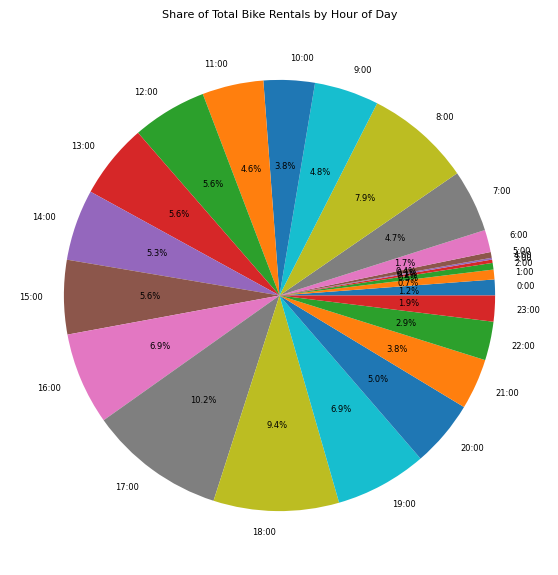

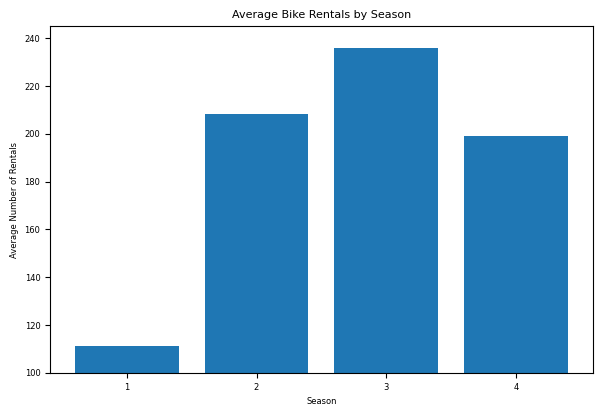

In [ ]:
def recreate_chart_a(data):
    """Recreate the original Chart A: pie chart of the share of rentals by hour of day."""
    totals = data.groupby("hr")["cnt"].sum()
    with plt.style.context("default"):                      # original default look
        fig, ax = plt.subplots(figsize=(7, 7))
        ax.pie(totals, labels=[f"{h}:00" for h in totals.index], autopct="%1.1f%%",
               textprops={"fontsize": 6})
        ax.set_title("Share of Total Bike Rentals by Hour of Day", fontsize=8)
        plt.show()


def recreate_chart_b(data):
    """Recreate the original Chart B: bar chart of average rentals by season (numbers 1-4)."""
    means = data.groupby("season")["cnt"].mean()
    with plt.style.context("default"):
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.bar(means.index, means.values)
        ax.set_xticks(means.index)
        ax.set_ylim(100, 245)                               # the original y-axis does not start at 0
        ax.set_title("Average Bike Rentals by Season", fontsize=8)
        ax.set_xlabel("Season", fontsize=6)
        ax.set_ylabel("Average Number of Rentals", fontsize=6)
        ax.tick_params(labelsize=6)
        plt.show()


recreate_chart_a(hourly)
recreate_chart_b(hourly)

##Problem 2 – Critique of the supplied charts

###Chart A: pie chart of the share of rentals by hour
**Strengths.** A pie chart works well when the message is about how a total's divided. In this case the two largest slices—17:00 and 18:00—do stand out clearly.

**Weaknesses.**
- **Many slices.** There are 24 slices, which's far too many for a pie chart to display clearly. Several hours have identical shares—12:00, 13:00 and 15:00 all show 5.6%—but the angles are too similar to tell them apart.

- **Unreadable small slices.** The labels for the hours from 0:00 to 6:00 overlap into a dark unreadable mess. The overnight rental shares are completely lost to the reader.

- **Colour carries no meaning.** The default colour scheme uses a 10-colour cycle that repeats than twice. As a result the same colour appears for hours adding no helpful information.

- **Time is hidden.** The hour of day is an ordered variable. A pie chart turns it into a circle breaking the flow. The reader cannot see the pattern of demand through the day. Recognize morning and evening peaks.

- **Small.** No message. The fonts are too small to read. The title only describes the chart it does not state the finding.

###Chart B: bar chart of the rentals by season
**Strengths.** A bar chart is a choice for comparing values across categories. The seasons are ordered correctly. The axes are. The title is clear.

**Weaknesses.**

- **Truncated y-axis.** The vertical axis starts at 100 instead of 0. Bar length is the visual cue so starting at 100 exaggerates differences. Season 1 appears about 8% as tall as Season 3 but the actual averages are 111 and 236. In reality Season 1 is half as large as Season 3.

- **Seasons shown as numbers 1–4**. The reader must guess what season "1" refers to. The real order is Winter, Spring, Summer, Fall. This is not shown.

- **No value. Tiny fonts.** There are no numbers on the bars so the exact values cannot be read. The text is too small to be legible.

- **One. No spread.** All bars are the shade of blue. The colour adds no value. Also showing only an average hides the variation in rentals within each season.

- **Unclear unit.** "Average Number of Rentals" does not say average per what. It should be clear that this is the average, per record.

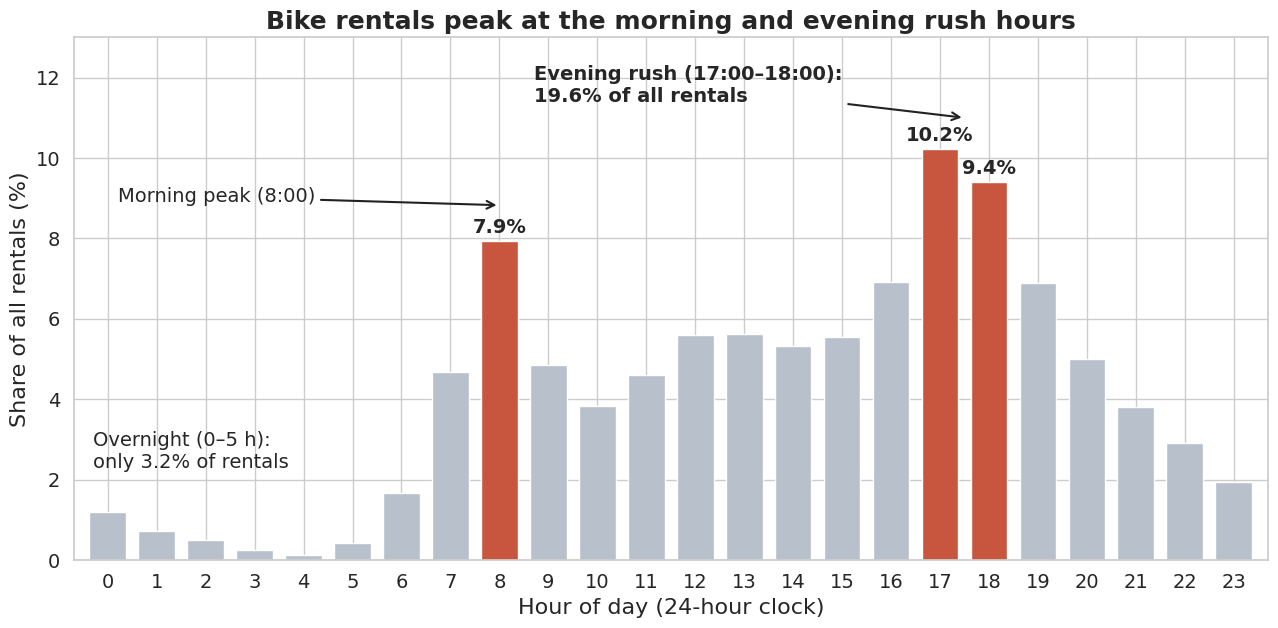

In [ ]:
def plot_redesigned_hourly_share(data):
    """Redesign of Chart A: bar chart of each hour's share of total rentals,
    with the three busiest hours highlighted."""
    totals = data.groupby("hr")["cnt"].sum()
    share = totals / totals.sum() * 100                  # percentage of all rentals

    # Highlight the three busiest hours, grey for the rest
    top3 = share.nlargest(3).index
    colours = ["#C8553D" if h in top3 else "#B8C0CC" for h in share.index]

    fig, ax = plt.subplots(figsize=(13, 6.5))
    ax.bar(share.index, share.values, color=colours, width=0.75)

    # Value labels only on the highlighted bars (labelling all 24 would be cluttered)
    for h in top3:
        ax.text(h, share[h] + 0.2, f"{share[h]:.1f}%", ha="center", fontsize=14, fontweight="bold")

    # Annotation 1: the evening rush
    evening = share[[17, 18]].sum()
    ax.annotate(f"Evening rush (17:00–18:00):\n{evening:.1f}% of all rentals",
                xy=(17.5, 11.0), xytext=(8.7, 11.4), fontsize=14, fontweight="bold",
                arrowprops=dict(arrowstyle="->", color="#222222", lw=1.5))

    # Annotation 2: the morning peak
    ax.annotate("Morning peak (8:00)", xy=(8, share[8] + 0.9), xytext=(0.2, 8.9), fontsize=14,
                arrowprops=dict(arrowstyle="->", color="#222222", lw=1.5))

    # Annotation 3: the quiet night hours
    night = share[0:6].sum()
    ax.text(-0.3, 2.3, f"Overnight (0–5 h):\nonly {night:.1f}% of rentals", fontsize=14)

    ax.set_xticks(range(24))
    ax.set_title("Bike rentals peak at the morning and evening rush hours")
    ax.set_xlabel("Hour of day (24-hour clock)")
    ax.set_ylabel("Share of all rentals (%)")
    ax.set_ylim(0, 13)
    ax.set_xlim(-0.7, 23.7)
    plt.tight_layout()
    plt.show()


plot_redesigned_hourly_share(hourly)

##Problem 2 – Chart A redesign: share of rentals by hour.

**Changes. Why they help.**

- I replaced the pie chart with a bar chart. The hour of day is an ordered variable so I placed the hours on the x‑axis in clock order. The reader can now follow the day from left to right. Compare bar heights. People judge bar heights accurately than pie angles.

- I used color to convey meaning. The three busiest hours—8:00, 17:00 and 18:00—are red while the other hours are grey. This directs the eye to the pattern. In the original colors. Carried no information.

- I reduced clutter. The unreadable overlapping labels are gone. Only the highlighted bars have value labels and the x‑axis shows every hour.

- I added annotations and a message title. The title now states the finding and three annotations point out the evening rush, the morning peak and the quiet night.

- I made the text readable. All fonts are 14 or larger. The y‑axis starts at zero.

**Interpretation.** Chart A shows a clear double‑peak shape in share of rentals by hour. The morning peak is at 8:00 accounting for 7.9% of all rentals. The biggest peak is in the evening at 17:00 with 10.2% and at 18:00 with 9.4%. Together those two hours make 19.6% of all rentals. Between the two peaks there is a plateau of about 5–6% per hour from 12:00 to 15:00. The overnight hours from 0 to 5 account for 3.2%. This pattern fits commuting to and, from work which is a hypothesis here because the file does not say why people ride. My additional chart tests this idea by comparing working days with weekends.

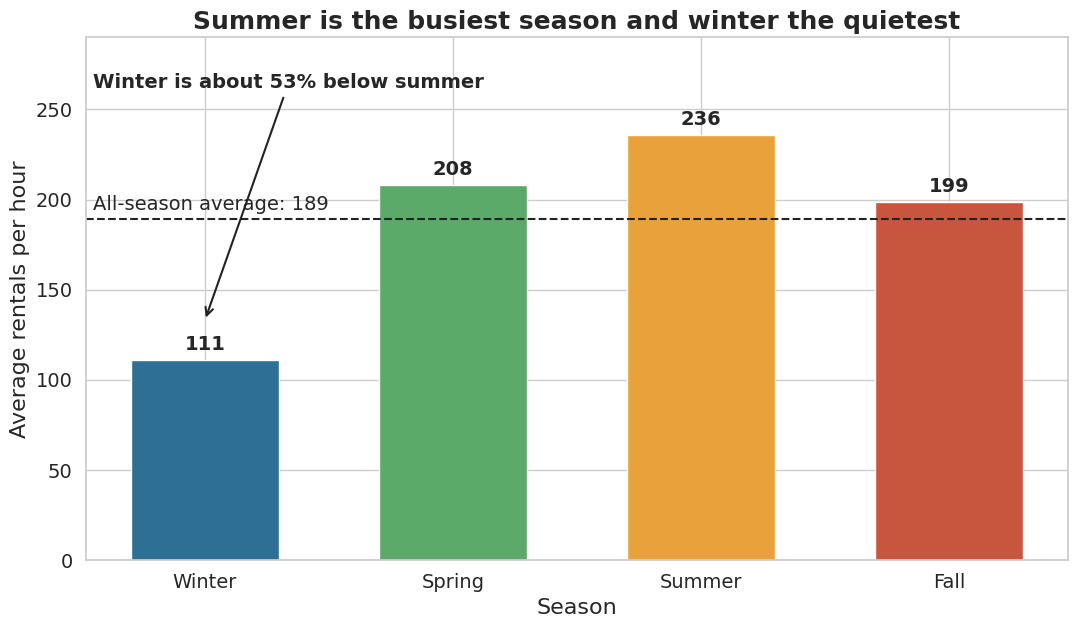

In [ ]:
def plot_redesigned_season_bars(data):
    """Redesign of Chart B: average rentals per hour by season, with a zero baseline,
    season names, value labels and a reference line for the overall average."""
    means = data.groupby("season_name")["cnt"].mean().reindex(SEASON_ORDER)
    overall = data["cnt"].mean()
    winter_drop = (1 - means["Winter"] / means["Summer"]) * 100

    fig, ax = plt.subplots(figsize=(11, 6.5))
    bars = ax.bar(means.index, means.values,
                  color=[SEASON_COLOURS[s] for s in means.index], width=0.6)

    # Value label on each bar
    ax.bar_label(bars, fmt="%.0f", padding=4, fontsize=14, fontweight="bold")

    # Reference line: the overall average across all seasons
    ax.axhline(overall, color="#222222", linestyle="--", linewidth=1.5)
    ax.text(-0.45, overall + 5, f"All-season average: {overall:.0f}", fontsize=14)

    # Annotation: how far winter is below summer
    ax.annotate(f"Winter is about {winter_drop:.0f}% below summer",
                xy=(0, means["Winter"] + 22), xytext=(-0.45, 262), fontsize=14, fontweight="bold",
                arrowprops=dict(arrowstyle="->", color="#222222", lw=1.5))

    ax.set_title("Summer is the busiest season and winter the quietest")
    ax.set_xlabel("Season")
    ax.set_ylabel("Average rentals per hour")
    ax.set_ylim(0, 290)                       # bars start at zero so lengths are honest
    plt.tight_layout()
    plt.show()


plot_redesigned_season_bars(hourly)

##Problem 2 – Chart B redesign: rentals by season

**Changes made and why they help**

- **Zero baseline.** The y-axis now starts at 0. Bar length is the encoding so a cut-off axis exaggerates differences. With the axis starting at 0 Winter correctly looks about half the height of Summer (111 vs 236) not a sliver.

- **Season names, not numbers.** The seasons are labelled Winter, Spring, Summer and Fall in calendar order so the reader does not have to guess what "1" means.

- **Value. A reference line.** Each bar shows its value and a dashed line shows the overall average (189) so it is easy to see which seasons are above or below it.

- **Colour with meaning.** Each season has its colour, which I reuse in Problem 1 so the colours link the two parts of the notebook.

- **Clear. Message.** The y-axis says "average rentals per hour" and the title states the finding. All fonts are 14 or above.

**Interpretation.** Summer is the season (236 rentals per hour) and winter the quietest (111) which is 53% lower. Spring (208) and Fall (199) are close to each other and above the overall average of 189. This matches what Problem 1 showed that rentals rise with temperature although the file does not say why. Temperature is a hypothesis here. One caution: the averages are per record and hours with no rentals are not recorded in the file so the true averages, per hour are slightly lower than shown.

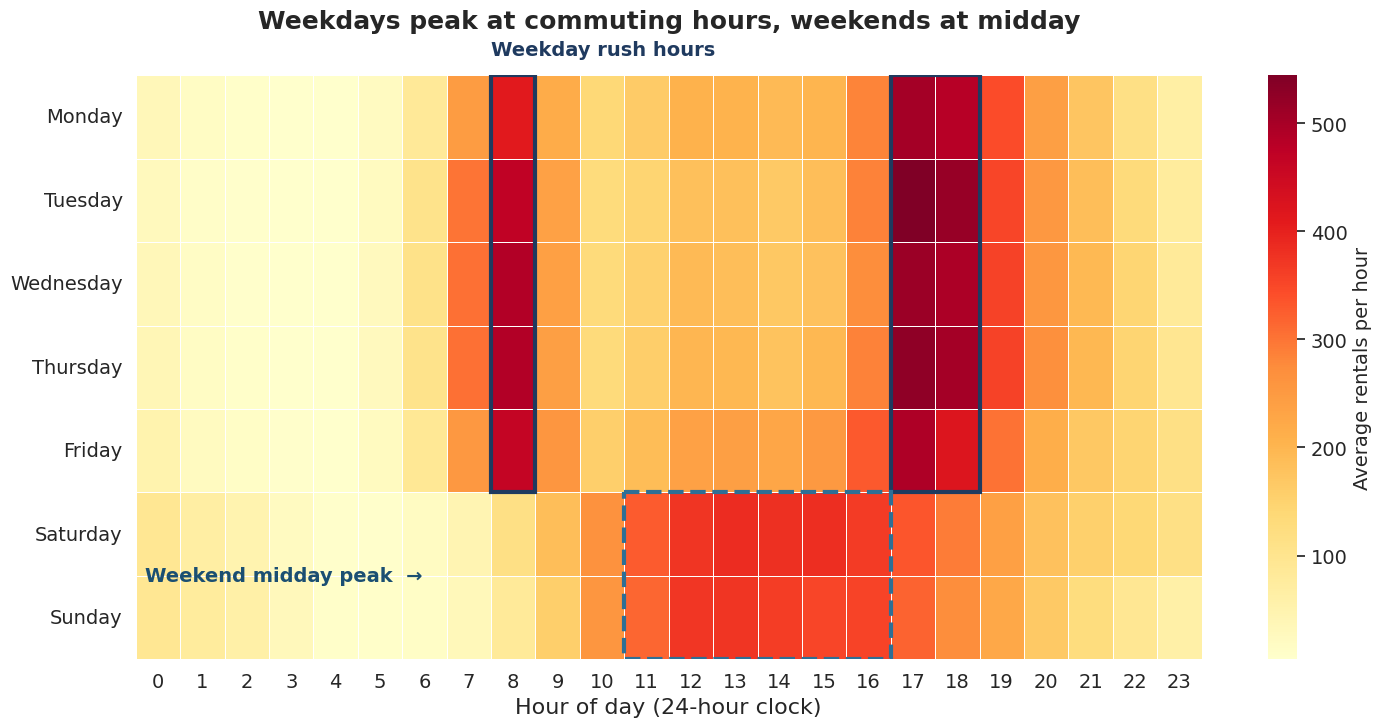

In [ ]:
from matplotlib.patches import Rectangle


def plot_weekday_hour_heatmap(data):
    """Heatmap of average rentals for every weekday and hour, with the key patterns outlined."""
    order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

    # Average rentals for each weekday (rows) and hour (columns)
    pivot = (data.pivot_table(index="day_name", columns="hr", values="cnt", aggfunc="mean")
                 .reindex(order))

    fig, ax = plt.subplots(figsize=(15, 7.5))
    sns.heatmap(pivot, cmap="YlOrRd", linewidths=0.6, linecolor="white",
                xticklabels=True, yticklabels=True, ax=ax)

    # Colour bar label and tick size (fonts must be 14 or above)
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=14)
    cbar.set_label("Average rentals per hour", fontsize=14)

    # Outline the weekday rush hours (8:00 and 17:00-18:00, Monday to Friday)
    ax.add_patch(Rectangle((8, 0), 1, 5, fill=False, edgecolor="#1F3A5F", linewidth=3))
    ax.add_patch(Rectangle((17, 0), 2, 5, fill=False, edgecolor="#1F3A5F", linewidth=3))
    # Outline the weekend midday peak (11:00-16:00, Saturday and Sunday)
    ax.add_patch(Rectangle((11, 5), 6, 2, fill=False, edgecolor="#2E6F95", linewidth=3, linestyle="--"))

    # Labels for the outlined areas
    ax.text(8, -0.2, "Weekday rush hours", fontsize=14, fontweight="bold",
            color="#1F3A5F", ha="left", va="bottom")
    ax.text(0.2, 6.0, "Weekend midday peak  →", fontsize=14, fontweight="bold",
            color="#1B4F72", ha="left", va="center")

    ax.set_title("Weekdays peak at commuting hours, weekends at midday", pad=34)
    ax.set_xlabel("Hour of day (24-hour clock)")
    ax.set_ylabel("")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


plot_weekday_hour_heatmap(hourly)

## Problem 2 – My chart: rentals by weekday and hour

**Why this chart.** Chart A showed patterns by hour. Chart B showed patterns by season but neither shows if the daily pattern is the same on every day of the week. A heatmap puts weekday on one axis and hour on the other with colour showing the number of rentals. This lets the reader compare 168 weekday–hour combinations all at once which would need seven line charts otherwise. I outlined the patterns and used a single-hue colour scale from pale yellow to dark red so that darker always means busier.

**What it shows.**

- **Weekdays have two rush hours.** Monday to Friday rentals rise at 8:00 (about 477 per hour on working days). Are highest at 17:00–18:00 (about 525 and 492). The busiest single cell is Tuesday at 17:00 ( 544).

- **Weekends look different.** There is no morning or evening rush. Instead rentals increase through the morning. Stay high from 11:00 to 16:00 (about 315–373 per hour peaking at 13:00).

- **Nights differ too.** Weekend nights are busier than weekday nights ( 91 vs 37 rentals at midnight) which fits people going out late at weekends.

**Interpretation.** The same rentals are used in two ways: commuting on working days and leisure on weekends. This explains the peak in the redesigned Chart A, which is really the weekday pattern and it is only a hypothesis because the file does not say why people ride. It also suggests that the system needs rentals near work areas at 8:00 and 17:00–18:00 on weekdays but near leisure areas around midday, on weekends.

# Bike Sharing Analysis: When Where and Why People Ride

**Module assessment – Individual Practical Exercises**

## About the data

The Capital Bikeshare dataset (UCI Machine Learning Repository) records bike rentals in Washington D.C. In 2011 and 2012 along with weather and calendar information. Problem 1 uses the file (`day.csv` 731 days). Problem 2 uses the file (`dataset_x.csv` 17,379 hours).

** variables:** `cnt` ( rentals) `casual` and `registered` (type of user) `season` `weathersit` (weather type) `temp` `hum` and `windspeed` (weather scaled to 0–1) `workingday` and `hr` (hour of day).

## The story

1. **Problem 1: what drives demand?** Temperature (Plot 1) weather type (Plot 2) and growth between years (Plot 3).

2. **Problem 2: when do people ride?** I. Redesign two supplied charts (hour of day and season). Add a new chart comparing weekdays and weekends.

## Data preparation notes

- No missing values or duplicate rows in either file and `casual + registered = cnt`, in every row.

- The Readme labels `season` as 1 = spring. Season 1 contains January so I used calendar seasons (1 = Winter).

- One day (10 March 2011) has a humidity of 0 which's not realistic. I replaced it using the days (Problem 1). It does not affect the Problem 2 charts.

- Temperature, humidity and wind speed are scaled. I converted them back to °C, % and km/h using the Readme factors.

## Conclusions: putting the story together

- **Weather and temperature set the daily level.** Rentals rise with temperature up to about 25 °C, then level off, and rain or snow cuts the typical day by about 62%.
- **The system grew between years.** 2012 had about 64% more rentals per day than 2011, in every month, so a fair comparison must account for the year.
- **Time of day and day of week set the pattern within a day.** Weekdays have commuter peaks at 8:00 and 17:00–18:00, and weekends have a broad midday peak.
- **Design lessons from Problem 2.** The pie chart hid the time pattern and the truncated bar chart exaggerated the seasons. Switching to ordered bars, a zero baseline, meaningful colour and annotations made the same data far easier to read.

**Limitations.** The data covers one city and two years, the weather is only a daily or hourly summary, and the explanations I give (commuting, growth of the system) are hypotheses, since the dataset has no information about riders' reasons.

**Reference.** Fanaee-T, H. and Gama, J. (2013) Bike Sharing [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset